# Chapter 28: Optimal Auctions, Multi-Unit Sales, and Package Bidding

This notebook reruns four worked examples from the chapter: VCG prices that a package bidder could block and the core payments that fix them, the optimal reserve for uniform values, full surplus extraction with correlated types, and demand reduction in a uniform-price auction. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def second_price_with_reserve(values, reserve=0.0):
    """Second-price auction with reserve r (myerson-optimal-auction-theorem, ch028).

    The highest value wins if it is at least r and pays max(second value, r); otherwise no sale.
    Book: values (80, 40), r = 50 -> pays 50, utility 30; r = 0 -> pays 40; (45, 40), r = 50 -> no sale.
    Returns {"sold", "winner" (index or None), "price", "utility"}.
    """
    vals = [float(v) for v in values]
    order = sorted(range(len(vals)), key=lambda i: -vals[i])
    top = order[0]
    if vals[top] < reserve:
        return {"sold": False, "winner": None, "price": 0.0, "utility": 0.0}
    second = vals[order[1]] if len(vals) > 1 else 0.0
    price = max(second, float(reserve))
    return {"sold": True, "winner": top, "price": price, "utility": vals[top] - price}


def virtual_value_uniform(v, hi=100.0, lo=0.0):
    """Virtual value v - (1 - F(v)) / f(v) for values uniform on [lo, hi] (myerson-optimal-auction-theorem).

    With lo = 0 this is 2v - hi. Book (ch028): phi(80) = 60, phi(45) = -10, phi(40) = -20, zero at 50.
    """
    return v - (hi - v)


def _best_allocation(bids, exclude=None):
    """Welfare-maximizing set of single-minded bids with disjoint packages (brute force)."""
    import itertools
    names = [n for n in bids if n != exclude]
    best, best_set = 0.0, ()
    for k in range(1, len(names) + 1):
        for combo in itertools.combinations(names, k):
            items = [i for n in combo for i in bids[n][0]]
            if len(items) != len(set(items)):
                continue
            w = sum(float(bids[n][1]) for n in combo)
            if w > best + 1e-12:
                best, best_set = w, combo
    return best, best_set


def vcg_payments(bids, packages=None):
    """VCG (Clarke pivot) payments for single-minded package bids.

    Principles: core-selecting-package-auctions (ch028), vickrey-clarke-groves-mechanism (ch029).
    ``bids`` maps bidder -> value; ``packages`` maps bidder -> iterable of items. (A bids dict of
    bidder -> (items, value) is also accepted with packages=None.) Payment of a winner i is
    W(without i) - (W - v_i). Book: Alice A 60, Ben B 60, Nora AB 100 -> locals win, pay 40 each,
    revenue 80; Nora 130 -> Nora wins, pays 120. ch029: X AB 140, Y A 80, Z B 75 -> pY 65, pZ 60;
    X 160 -> pX 155. Returns {"winners", "welfare", "payments", "revenue", "utilities"}.
    """
    if packages is not None:
        bids = {n: (tuple(packages[n]), float(v)) for n, v in bids.items()}
    welfare, winners = _best_allocation(bids)
    payments, utilities = {}, {}
    for n in winners:
        w_without, _ = _best_allocation(bids, exclude=n)
        payments[n] = w_without - (welfare - float(bids[n][1]))
        utilities[n] = float(bids[n][1]) - payments[n]
    return {"winners": list(winners), "welfare": welfare, "payments": payments,
            "revenue": sum(payments.values()), "utilities": utilities}


def min_core_symmetric(vcg, block_value, caps):
    """Minimum-revenue core point with a symmetric tie-break (core-selecting-package-auctions, ch028).

    ``vcg`` lists the winners' VCG payments (lower bounds), ``block_value`` is the blocking
    coalition's bid, ``caps`` the winners' bids (individual rationality). If VCG revenue already
    covers the block, VCG is in the core. Otherwise raise payments equally until they sum to the
    block value. Book: VCG (40, 40), block 100, caps (60, 60) -> (50, 50).
    Returns {"payments", "revenue", "blocked", "feasible"}.
    """
    vcg = [float(v) for v in vcg]
    total = sum(vcg)
    if total >= block_value:
        return {"payments": vcg, "revenue": total, "blocked": False, "feasible": True}
    extra = (block_value - total) / len(vcg)
    pay = [v + extra for v in vcg]
    feasible = all(p <= c + 1e-9 for p, c in zip(pay, caps))
    return {"payments": pay, "revenue": sum(pay), "blocked": True, "feasible": feasible}


def cremer_mclean_lottery(cond_H, cond_L, rent_H, rent_L=0.0):
    """Side bet on the rival's report that extracts the interim rents (cremer-mclean-full-surplus-extraction).

    cond_H = Pr(rival H | own H), cond_L = Pr(rival H | own L). Solve
    cond_H x - (1 - cond_H) y = rent_H and cond_L x - (1 - cond_L) y = rent_L for the charge x
    (rival reports H) and rebate y (rival reports L). Returns (x, y), or None when the
    conditional beliefs coincide (rank condition fails). Book: (0.8, 0.2, 20) -> (80/3, 20/3).
    """
    det = -cond_H * (1 - cond_L) + cond_L * (1 - cond_H)
    if abs(det) < 1e-12:
        return None
    x = (-rent_H * (1 - cond_L) + rent_L * (1 - cond_H)) / det
    y = (cond_H * rent_L - cond_L * rent_H) / det
    return x, y


def uniform_price_multiunit(bids, supply):
    """Uniform-price auction: top ``supply`` marginal bids win, each pays the highest rejected bid
    (zero reserve). Principle: demand-reduction (ch028).

    ``bids`` maps bidder -> list of marginal bids. Book: A (100, 90), B (80, 70), 3 units -> price 70,
    A wins 2; A bids (100, 0) -> price 0. Returns {"units", "price", "winning"} where winning lists
    (bidder, bid) pairs; ties at the cutoff go to the bidder listed first.
    """
    ladder = sorted(((float(b), n) for n, bl in bids.items() for b in bl), key=lambda t: -t[0])
    win = ladder[:supply]
    rejected = ladder[supply:]
    price = rejected[0][0] if rejected else 0.0
    units = {n: 0 for n in bids}
    for b, n in win:
        units[n] += 1
    return {"units": units, "price": max(price, 0.0), "winning": [(n, b) for b, n in win]}


def vcg_multiunit(values, supply):
    """Multi-unit Vickrey payments with decreasing marginal values (demand-reduction, ch028).

    ``values`` maps bidder -> marginal values. Each bidder pays the others' best value without it
    minus the others' value in the efficient allocation. Book: A (100, 90), B (80, 70), 3 units ->
    A pays 150 - 80 = 70, utility 120. Returns {"units", "payments", "utilities", "welfare"}.
    """
    def alloc(names):
        ladder = sorted(((float(v), n) for n in names for v in values[n]), key=lambda t: -t[0])[:supply]
        return ladder
    eff = alloc(list(values))
    units = {n: sum(1 for _, m in eff if m == n) for n in values}
    payments, utilities = {}, {}
    for n in values:
        others = [m for m in values if m != n]
        without = sum(v for v, _ in alloc(others))
        others_in_eff = sum(v for v, m in eff if m != n)
        payments[n] = without - others_in_eff
        utilities[n] = sum(v for v, m in eff if m == n) - payments[n]
    return {"units": units, "payments": payments, "utilities": utilities, "welfare": sum(v for v, _ in eff)}


plt.rcParams.update(HOUSE_RC)


auctions = SimpleNamespace(second_price_with_reserve=second_price_with_reserve, virtual_value_uniform=virtual_value_uniform, vcg_payments=vcg_payments, min_core_symmetric=min_core_symmetric, cremer_mclean_lottery=cremer_mclean_lottery, uniform_price_multiunit=uniform_price_multiunit, vcg_multiunit=vcg_multiunit)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'core-selecting-package-auctions': {'alice': 60,
                                     'ben': 60,
                                     'nora': 100,
                                     'local_value': 120,
                                     'vcg_each': 40,
                                     'vcg_revenue': 80,
                                     'block_offer': 90,
                                     'nora_block_utility': 10,
                                     'core': (50, 50),
                                     'nora_cf': 130,
                                     'nora_cf_pays': 120,
                                     'nora_cf_utility': 10},
 'myerson-optimal-auction-theorem': {'hi': 100,
                                     'reserve': 50,
                                     'profile': (80, 40),
                                     'phi_80': 60,
                                     'pay': 50,
                                     'utility': 30,
                                     'gain': 10,
                                     'low_profile': (45, 40),
                                     'phi_45': -10,
                                     'phi_40': -20,
                                     'pay_no_reserve_low': 40,
                                     'rev_optimal': 41.666666666666664,
                                     'rev_optimal_printed_as': 41.67,
                                     'rev_no_reserve': 33.333333333333336,
                                     'rev_no_reserve_printed_as': 33.33,
                                     'expected_gain_printed_as': 8.33},
 'cremer-mclean-full-surplus-extraction': {'value': 100,
                                           'p_HH': 0.4,
                                           'p_HL': 0.1,
                                           'cond_H': 0.8,
                                           'cond_L': 0.2,
                                           'rent_H': 20,
                                           'charge': 26.666666666666668,
                                           'rebate': 6.666666666666667,
                                           'surplus': 60,
                                           'sp_revenue': 40,
                                           'total_revenue': 60,
                                           'independent_p_HH': 0.25},
 'demand-reduction': {'supply': 3,
                      'A': (100, 90),
                      'B': (80, 70),
                      'price': 70,
                      'A_truthful': 50,
                      'A_reduced': 100,
                      'value_truthful': 270,
                      'value_reduced': 250,
                      'loss': 20,
                      'vickrey_pay': 70,
                      'vickrey_utility': 120},
 'constructed': {'core-selecting-package-auctions': {'nora_values': [90, 110]},
                 'myerson-optimal-auction-theorem': {'vH': [60], 'vL': [30]},
                 'cremer-mclean-full-surplus-extraction': {'p_HH': [0.3]},
                 'demand-reduction': {'a2': [60, 75], 'b2': [50]}}}


def core_picture(n=100):
    N = n
    b = BV["core-selecting-package-auctions"]
    alice, ben = b["alice"], b["ben"]
    res = auctions.vcg_payments({"Alice": alice, "Ben": ben, "Nora": N},
                                {"Alice": ["A"], "Ben": ["B"], "Nora": ["A", "B"]})
    locals_win = "Nora" not in res["winners"]
    fig, ax = new_figure()
    if locals_win:
        pa, pb = res["payments"]["Alice"], res["payments"]["Ben"]
        core = auctions.min_core_symmetric([pa, pb], N, [alice, ben])
        ca, cb = core["payments"]
        gap = N - res["revenue"]
        bar_compare(ax, ["Nora's bid", "VCG revenue", "Core revenue"], [N, res["revenue"], core["revenue"]],
                    colors=["gold", "terracotta", "teal"],
                    value_labels=[num(N, 0), num(res["revenue"], 0), num(core["revenue"], 0)],
                    ylabel="Payment ($)", xlabel="Amount")
        ax.set_ylim(0, 145)
        hline(ax, N, f"blocking gap {num(gap, 0)}", col="gold", x_frac=0.36)
        metrics = {"Winners": "Alice and Ben", "VCG payment each": num(pa, 0), "VCG revenue": num(res["revenue"], 0),
                   "Blocking gap": num(gap, 0), "Core payments (Alice, Ben)": f"({num(ca, 0)}, {num(cb, 0)})",
                   "Nora's payment": "none (she loses)"}
        interp = (f"The locals create {alice} + {ben} = {alice + ben}, more than Nora's {N}, so they win. Removing Alice "
                  f"leaves Nora's {N} as the best alternative, so Alice pays {N} - {ben} = {num(pa, 0)}, and Ben pays "
                  f"the same. VCG revenue is {num(res['revenue'], 0)}, which is {num(gap, 0)} below Nora's bid, so "
                  f"the seller and Nora could block. The core requires p_A + p_B >= {N}; the symmetric minimum-revenue "
                  f"point is ({num(ca, 0)}, {num(cb, 0)}), within each local's bid of 60.")
        steps = [f"{alice} + {ben} = {alice + ben} > {N}",
                 f"p_A = {N} - {ben} = {num(pa, 0)}, p_B = {N} - {alice} = {num(pb, 0)}",
                 f"VCG revenue = {num(pa, 0)} + {num(pb, 0)} = {num(res['revenue'], 0)} < {N}",
                 f"Core: p_A + p_B = {N}, symmetric ({num(ca, 0)}, {num(cb, 0)})"]
        alt = (f"Bars: Nora's bid {N}, VCG revenue {num(res['revenue'], 0)}, core revenue {num(core['revenue'], 0)}. "
               f"A dashed line at {N} shows the blocking gap of {num(gap, 0)} above VCG revenue.")
    else:
        pn = res["payments"]["Nora"]
        un = res["utilities"]["Nora"]
        bar_compare(ax, ["Nora's bid", "Nora pays", "Locals' value"], [N, pn, alice + ben],
                    colors=["gold", "terracotta", "teal"],
                    value_labels=[num(N, 0), num(pn, 0), num(alice + ben, 0)], ylabel="Payment ($)", xlabel="Amount")
        ax.set_ylim(0, 145)
        metrics = {"Winners": "Nora", "VCG payment each": "none (the locals lose)", "VCG revenue": num(pn, 0),
                   "Blocking gap": "0 (no coalition can block)", "Core payments (Alice, Ben)": "no adjustment needed",
                   "Nora's payment": f"{num(pn, 0)} (utility {num(un, 0)})"}
        interp = (f"Nora's {N} exceeds the locals' {alice} + {ben} = {alice + ben}, so she wins both licenses and pays "
                  f"the {num(pn, 0)} the locals could create without her, keeping {N} - {num(pn, 0)} = {num(un, 0)}. "
                  f"The seller and the locals can create only {alice + ben}, so revenue of {num(pn, 0)} already "
                  f"meets their core inequality and VCG needs no adjustment.")
        steps = [f"{N} > {alice} + {ben} = {alice + ben}", f"p_N = {alice + ben} - 0 = {num(pn, 0)}",
                 f"Nora's utility = {N} - {num(pn, 0)} = {num(un, 0)}"]
        alt = (f"Bars: Nora's bid {N}, her VCG payment {num(pn, 0)} and the locals' combined value {alice + ben}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def myerson_picture(vh=80, vl=40, r=50):
    vH, vL = vh, vl
    b = BV["myerson-optimal-auction-theorem"]
    hi = b["hi"]
    ph, pl = auctions.virtual_value_uniform(vH, hi), auctions.virtual_value_uniform(vL, hi)
    res = auctions.second_price_with_reserve([vH, vL], r)
    base = auctions.second_price_with_reserve([vH, vL], 0)
    rev, rev0 = res["price"], base["price"]
    exp_rev = 125 / 3 if r == 50 else 100 / 3
    vs = np.linspace(0, 100, 50)
    fig, ax = new_figure()
    ax.plot(vs, [auctions.virtual_value_uniform(v, hi) for v in vs], color=PALETTE["navy"], linewidth=2,
            label="virtual value 2v - 100")
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.legend(loc="lower right", frameon=False)
    mark(ax, vH, ph, f"phi({vH}) = {num(ph, 0)}", col="teal", dx=8, dy=-6, va="top")
    mark(ax, vL, pl, f"phi({vL}) = {num(pl, 0)}", col="terracotta", dx=8, dy=-6, va="top")
    if r > 0:
        vline(ax, r, f"reserve {r}", col="gold", y_frac=0.97, ha="right")
    ax.set_xlim(0, 105)
    ax.set_ylim(-110, 115)
    ax.set_xlabel("Bidder value v")
    ax.set_ylabel("Virtual value phi(v)")
    outcome = (f"the bidder with value {vH} wins and pays max({vL}, {r}) = {num(rev, 0)}" if res["sold"] and r > 0
               else f"the bidder with value {vH} wins and pays the second value {num(rev, 0)}" if res["sold"]
               else f"there is no sale because {vH} is below {r}")
    diff = rev - rev0
    metrics = {"phi(higher value)": num(ph, 0), "phi(lower value)": num(pl, 0),
               "Outcome": "sale" if res["sold"] else "no sale (both below the reserve)",
               "Payment": num(rev, 0), "Winner utility": num(res["utility"], 0) if res["sold"] else "none (no sale)",
               "Realized revenue change from the reserve": f"{'+' if diff > 0 else ''}{num(diff, 0)}",
               "Expected revenue of this format": num(exp_rev)}
    interp = (f"With values uniform on [0, 100], phi(v) = 2v - 100, so phi({vH}) = 2 x {vH} - 100 = {num(ph, 0)} "
              f"and phi({vL}) = 2 x {vL} - 100 = {num(pl, 0)}. With reserve {r}, {outcome}. Without a reserve the payment would be {num(rev0, 0)}, "
              f"so the reserve changes realized revenue by {num(diff, 0)} in this profile. Expected revenue is "
              f"{num(exp_rev)} with this format, against 41.67 with reserve 50 and 33.33 with none.")
    steps = [f"phi({vH}) = 2 x {vH} - 100 = {num(ph, 0)}", f"phi({vL}) = 2 x {vL} - 100 = {num(pl, 0)}",
             (f"Payment = max({vL}, {r}) = {num(rev, 0)}, utility = {vH} - {num(rev, 0)} = {num(res['utility'], 0)}"
              if res["sold"] else f"{vH} < {r}: no sale, revenue 0"),
             f"Change from no reserve = {num(rev, 0)} - {num(rev0, 0)} = {num(diff, 0)}"]
    alt = (f"The virtual value line 2v - 100 crosses zero at 50. Points mark phi({vH}) = {num(ph, 0)} and "
           f"phi({vL}) = {num(pl, 0)}. " + (f"A dashed line marks the reserve at {r}." if r > 0 else "No reserve."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cremer_picture(a=0.4):
    value = BV["cremer-mclean-full-surplus-extraction"]["value"]
    off = 0.5 - a
    cH, cL = a / 0.5, off / 0.5
    rent = (1 - cH) * value
    lot = auctions.cremer_mclean_lottery(cH, cL, rent)
    surplus = (1 - a) * value
    sp = a * value
    fig, ax = new_figure()
    if lot is not None:
        x, y = lot
        total = sp + 2 * 0.5 * rent
        bar_compare(ax, ["Efficient surplus", "Second-price revenue", "Revenue with lottery"], [surplus, sp, total],
                    colors=["gold", "navy", "teal"], value_labels=[num(surplus), num(sp), num(total)],
                    ylabel="Expected value ($)", xlabel="Measure")
        metrics = {"Pr(B=H | A=H)": num(cH), "Pr(B=H | A=L)": num(cL), "Interim rent of H": num(rent),
                   "Charge if rival reports H": num(x), "Rebate if rival reports L": num(y),
                   "Efficient surplus": num(surplus), "Second-price revenue": num(sp), "Total revenue": num(total)}
        interp = (f"With Pr(H,H) = {num(a)}, Pr(B=H | A=H) = {num(a)}/0.5 = {num(cH)} and Pr(B=H | A=L) = "
                  f"{num(off)}/0.5 = {num(cL)}. The high type's second-price rent is {num(1 - cH)} x 100 = "
                  f"{num(rent)}. A charge of {num(x, 3)} when the rival reports H and a rebate of {num(y, 3)} when it "
                  f"reports L cost the high type {num(cH)} x {num(x, 3)} - {num(1 - cH)} x {num(y, 3)} = {num(rent, 3)} "
                  f"and the low type {num(cL)} x {num(x, 3)} - {num(1 - cL)} x {num(y, 3)} = 0. Revenue rises from "
                  f"{num(sp)} to {num(total)}, the whole surplus.")
        steps = [f"Pr(B=H | A=H) = {num(a)} / 0.5 = {num(cH)}", f"Rent of H = {num(1 - cH)} x 100 = {num(rent)}",
                 f"{num(cH)} x {num(x, 3)} - {num(1 - cH)} x {num(y, 3)} = {num(cH * x - (1 - cH) * y, 3)}",
                 f"{num(cL)} x {num(x, 3)} - {num(1 - cL)} x {num(y, 3)} = {num(cL * x - (1 - cL) * y, 3)}",
                 f"Total = {num(sp)} + 2 x 0.5 x {num(rent)} = {num(total)} = surplus {num(surplus)}"]
        alt = (f"Bars: efficient surplus {num(surplus)}, second-price revenue {num(sp)}, revenue with the lottery "
               f"{num(total)}.")
    else:
        bar_compare(ax, ["Efficient surplus", "Second-price revenue"], [surplus, sp], colors=["gold", "navy"],
                    value_labels=[num(surplus), num(sp)], ylabel="Expected value ($)", xlabel="Measure")
        ax.text(0.97, 0.9, "rank condition fails", transform=ax.transAxes, ha="right", va="top", fontsize=11,
                color=PALETTE["terracotta"])
        metrics = {"Pr(B=H | A=H)": num(cH), "Pr(B=H | A=L)": num(cL), "Interim rent of H": num(rent),
                   "Charge if rival reports H": "undefined (rank condition fails)",
                   "Rebate if rival reports L": "undefined (rank condition fails)",
                   "Efficient surplus": num(surplus), "Second-price revenue": num(sp),
                   "Total revenue": f"{num(sp)} (no lottery can add to it)"}
        interp = (f"With Pr(H,H) = {num(a)}, types are independent: Pr(B=H | A=H) = Pr(B=H | A=L) = {num(cH)}. Any bet "
                  f"on the rival's report then has the same expected cost for both types, so it cannot charge the "
                  f"high type {num(rent)} and the low type 0. The rank condition fails and revenue stays at "
                  f"{num(a)} x 100 = {num(sp)} of the {num(surplus)} surplus.")
        steps = [f"Pr(B=H | A=H) = {num(a)} / 0.5 = {num(cH)}", f"Pr(B=H | A=L) = {num(off)} / 0.5 = {num(cL)}",
                 "Equal beliefs: the two equations have no solution", f"Revenue = {num(a)} x 100 = {num(sp)}"]
        alt = f"Bars: efficient surplus {num(surplus)} and second-price revenue {num(sp)}; the rank condition fails."
    ax.set_ylim(0, 95)
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def reduction_picture(a2=90, b2=70):
    b = BV["demand-reduction"]
    supply, a1, b1 = b["supply"], b["A"][0], b["B"][0]
    tru = auctions.uniform_price_multiunit({"A": [a1, a2], "B": [b1, b2]}, supply)
    red = auctions.uniform_price_multiunit({"A": [a1, 0], "B": [b1, b2]}, supply)
    p = tru["price"]
    a_won = [a1, a2][:tru["units"]["A"]]
    u_tru = sum(v - p for v in a_won)
    u_red = a1 - red["price"]
    val_tru = sum(v for _, v in tru["winning"])
    val_red = a1 + b1 + b2
    loss = val_tru - val_red
    vick = auctions.vcg_multiunit({"A": [a1, a2], "B": [b1, b2]}, supply)
    u_vick = vick["utilities"]["A"]
    best, is_tie = tie_or_winner("truthful under Vickrey", u_vick, "shading", u_red)
    fig, ax = new_figure()
    bar_compare(ax, ["A truthful, uniform", "A shades, uniform", "A truthful, Vickrey"], [u_tru, u_red, u_vick],
                colors=["navy", "terracotta", "teal"], value_labels=[num(u_tru, 0), num(u_red, 0), num(u_vick, 0)],
                ylabel="A's utility ($)", xlabel="Bidding rule")
    ax.set_ylim(0, 170)
    terms = " + ".join(f"({num(v, 0)} - {num(p, 0)})" for v in a_won)
    metrics = {"Truthful clearing price": num(p, 0), "A's truthful utility": num(u_tru, 0),
               "A's utility when shading": num(u_red, 0), "Efficiency loss from shading": num(loss, 0),
               "A's truthful utility under Vickrey": num(u_vick, 0),
               "Vickrey vs shading": "tie" if is_tie else best}
    shade = "gains" if u_red > u_tru else "does not gain"
    interp = (f"Truthful bids 100, {a2}, 80 and {b2}: the top three win and the price is the highest rejected bid, "
              f"{num(p, 0)}. A earns {terms} = {num(u_tru, 0)}. Bidding 0 for its second unit makes the price 0, so A "
              f"earns 100 - 0 = 100 and {shade} by shading. "
              + (f"Value falls from {num(val_tru, 0)} to {num(val_red, 0)}, a loss of {num(loss, 0)}." if loss > 0 else
                 f"A wins only one unit even when truthful, so value stays at {num(val_tru, 0)}: "
                 f"{num(val_tru, 0)} - {num(val_red, 0)} = 0 lost.")
              + f" Under Vickrey, A's truthful utility is {num(u_vick, 0)}"
              + (", exactly the 100 from shading, a tie." if is_tie else
                 (", more than the 100 from shading." if u_vick > u_red else ", less than the 100 from shading.")))
    steps = [f"Truthful price = highest rejected bid = {num(p, 0)}", f"A truthful: {terms} = {num(u_tru, 0)}",
             "A shades: 100 - 0 = 100",
             f"Value: {num(val_tru, 0)} - {num(val_red, 0)} = {num(loss, 0)} lost",
             f"Vickrey: A pays {num(b1 + b2, 0)} - {num(b1 + b2 - vick['payments']['A'], 0)} = "
             f"{num(vick['payments']['A'], 0)}, utility {num(u_vick, 0)}"]
    alt = (f"Bars of A's utility: {num(u_tru, 0)} truthful under the uniform price, {num(u_red, 0)} when shading, "
           f"{num(u_vick, 0)} truthful under Vickrey.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Core-selecting package auctions: when VCG prices invite a blocking deal

Alice bids 60 for license A, Ben 60 for B, Nora 100 for the package AB.

$$60+60=120>100, \qquad p_A^{VCG}=100-60=40, \qquad p_A+p_B\geq100, \qquad (p_A,p_B)=(50,50)$$

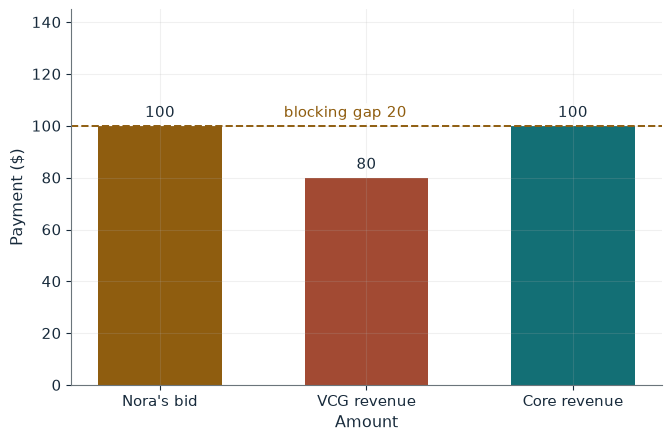

Winners                     Alice and Ben
VCG payment each            40
VCG revenue                 80
Blocking gap                20
Core payments (Alice, Ben)  (50, 50)
Nora's payment              none (she loses)

Worked steps:
  1. 60 + 60 = 120 > 100
  2. p_A = 100 - 60 = 40, p_B = 100 - 60 = 40
  3. VCG revenue = 40 + 40 = 80 < 100
  4. Core: p_A + p_B = 100, symmetric (50, 50)

The locals create 60 + 60 = 120, more than Nora's 100, so they win. Removing Alice leaves Nora's 100 as the best alternative, so Alice pays 100 - 60 = 40, and Ben pays the same. VCG revenue is 80, which is 20 below Nora's bid, so the seller and Nora could block. The core requires p_A + p_B >= 100; the symmetric minimum-revenue point is (50, 50), within each local's bid of 60.


In [2]:
show(core_picture(n=100))

Change one input, `n`, and hold the others at the book's values:

In [3]:
sweep(core_picture, 'n', [90, 100, 110, 130], {}, ['Winners', 'VCG revenue', 'Blocking gap', 'Core payments (Alice, Ben)'])

n | Winners | VCG revenue | Blocking gap | Core payments (Alice, Ben)
90 | Alice and Ben | 60 | 30 | (45, 45)
100 | Alice and Ben | 80 | 20 | (50, 50)
110 | Alice and Ben | 100 | 10 | (55, 55)
130 | Nora | 120 | 0 (no coalition can block) | no adjustment needed


VCG charges each local only 40, so revenue of 80 sits 20 below Nora's bid; the symmetric core point (50, 50) closes the gap. Once Nora bids 130 she wins, pays 120 and no coalition can block.

## 2. Myerson optimal auction: the reserve that sometimes refuses to sell

Two values uniform on [0, 100]; the optimal reserve is where the virtual value is zero.

$$\phi(v)=v-\frac{1-v/100}{1/100}=2v-100, \qquad \frac12(50)+\frac14\left(\frac{200}{3}\right)=\frac{125}{3}\approx41.67$$

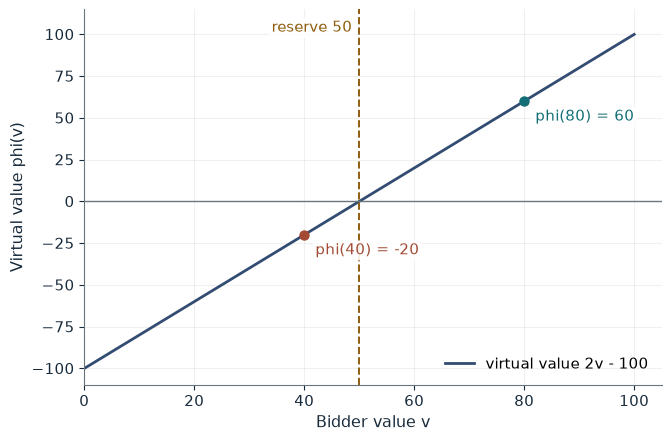

phi(higher value)                         60
phi(lower value)                          -20
Outcome                                   sale
Payment                                   50
Winner utility                            30
Realized revenue change from the reserve  +10
Expected revenue of this format           41.67

Worked steps:
  1. phi(80) = 2 x 80 - 100 = 60
  2. phi(40) = 2 x 40 - 100 = -20
  3. Payment = max(40, 50) = 50, utility = 80 - 50 = 30
  4. Change from no reserve = 50 - 40 = 10

With values uniform on [0, 100], phi(v) = 2v - 100, so phi(80) = 2 x 80 - 100 = 60 and phi(40) = 2 x 40 - 100 = -20. With reserve 50, the bidder with value 80 wins and pays max(40, 50) = 50. Without a reserve the payment would be 40, so the reserve changes realized revenue by 10 in this profile. Expected revenue is 41.67 with this format, against 41.67 with reserve 50 and 33.33 with none.


In [4]:
show(myerson_picture(vh=80, vl=40, r=50))

Change one input, `vh`, and hold the others at the book's values:

In [5]:
sweep(myerson_picture, 'vh', [45, 60, 80], {'vl': 40, 'r': 50}, ['Outcome', 'Payment', 'Realized revenue change from the reserve'])

vh | Outcome | Payment | Realized revenue change from the reserve
45 | no sale (both below the reserve) | 0 | -40
60 | sale | 50 | +10
80 | sale | 50 | +10


With values 80 and 40 the reserve lifts the payment from 40 to 50. With 45 and 40 there is no sale and 40 is lost in that profile, yet expected revenue rises from 33.33 to 41.67.

## 3. Cremer-McLean: correlated types let the seller take everything

Values 100 (H) or 0 (L), Pr(H,H) = Pr(L,L) = 0.4.

$$\Pr(B=H\mid A=H)=\frac{0.4}{0.5}=0.8, \qquad 0.8\left(\frac{80}{3}\right)-0.2\left(\frac{20}{3}\right)=20, \qquad 0.2\left(\frac{80}{3}\right)-0.8\left(\frac{20}{3}\right)=0$$

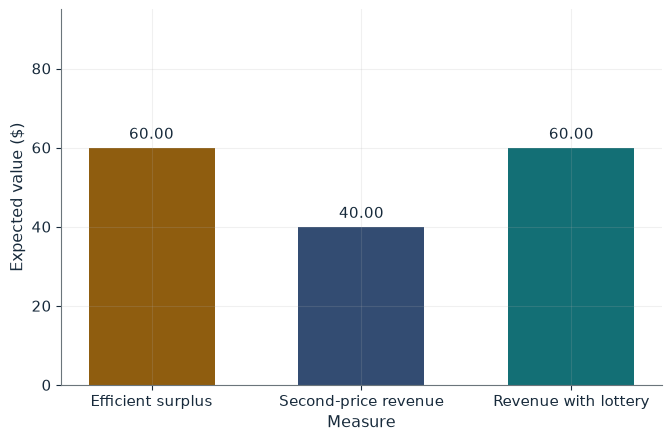

Pr(B=H | A=H)              0.80
Pr(B=H | A=L)              0.20
Interim rent of H          20.00
Charge if rival reports H  26.67
Rebate if rival reports L  6.67
Efficient surplus          60.00
Second-price revenue       40.00
Total revenue              60.00

Worked steps:
  1. Pr(B=H | A=H) = 0.40 / 0.5 = 0.80
  2. Rent of H = 0.20 x 100 = 20.00
  3. 0.80 x 26.667 - 0.20 x 6.667 = 20.000
  4. 0.20 x 26.667 - 0.80 x 6.667 = 0.000
  5. Total = 40.00 + 2 x 0.5 x 20.00 = 60.00 = surplus 60.00

With Pr(H,H) = 0.40, Pr(B=H | A=H) = 0.40/0.5 = 0.80 and Pr(B=H | A=L) = 0.10/0.5 = 0.20. The high type's second-price rent is 0.20 x 100 = 20.00. A charge of 26.667 when the rival reports H and a rebate of 6.667 when it reports L cost the high type 0.80 x 26.667 - 0.20 x 6.667 = 20.000 and the low type 0.20 x 26.667 - 0.80 x 6.667 = 0. Revenue rises from 40.00 to 60.00, the whole surplus.


In [6]:
show(cremer_picture(a=0.4))

Change one input, `a`, and hold the others at the book's values:

In [7]:
sweep(cremer_picture, 'a', [0.4, 0.3, 0.25], {}, ['Charge if rival reports H', 'Rebate if rival reports L', 'Total revenue'])

a | Charge if rival reports H | Rebate if rival reports L | Total revenue
0.4 | 26.67 | 6.67 | 60.00
0.3 | 120.00 | 80.00 | 70.00
0.25 | undefined (rank condition fails) | undefined (rank condition fails) | 25.00 (no lottery can add to it)


A charge of 26.67 and a rebate of 6.67 raise revenue from 40 to the full surplus of 60. Weaker correlation needs far larger bets (120 and 80 at 0.3), and with independent types none works.

## 4. Demand reduction: bidding for less to pay less

Three permits; A values (100, 90), B values (80, 70); winners pay the highest rejected bid.

$$(100-70)+(90-70)=50, \qquad 100-0=100, \qquad 100+90-70=120$$

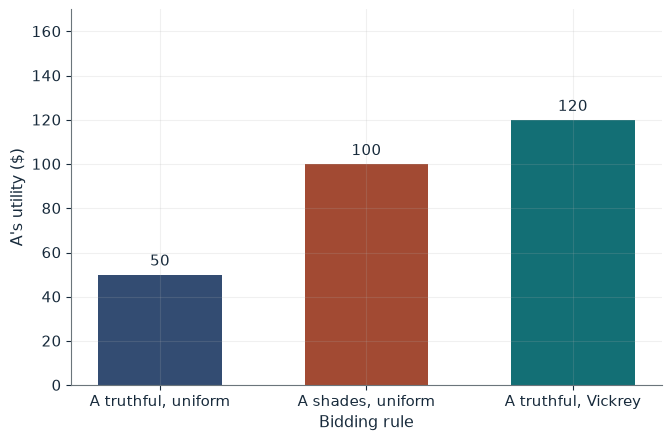

Truthful clearing price             70
A's truthful utility                50
A's utility when shading            100
Efficiency loss from shading        20
A's truthful utility under Vickrey  120
Vickrey vs shading                  truthful under Vickrey

Worked steps:
  1. Truthful price = highest rejected bid = 70
  2. A truthful: (100 - 70) + (90 - 70) = 50
  3. A shades: 100 - 0 = 100
  4. Value: 270 - 250 = 20 lost
  5. Vickrey: A pays 150 - 80 = 70, utility 120

Truthful bids 100, 90, 80 and 70: the top three win and the price is the highest rejected bid, 70. A earns (100 - 70) + (90 - 70) = 50. Bidding 0 for its second unit makes the price 0, so A earns 100 - 0 = 100 and gains by shading. Value falls from 270 to 250, a loss of 20. Under Vickrey, A's truthful utility is 120, more than the 100 from shading.


In [8]:
show(reduction_picture(a2=90, b2=70))

Change one input, `b2`, and hold the others at the book's values:

In [9]:
sweep(reduction_picture, 'b2', [50, 70], {'a2': 90}, ['Truthful clearing price', "A's truthful utility", 'Efficiency loss from shading'])

b2 | Truthful clearing price | A's truthful utility | Efficiency loss from shading
50 | 50 | 90 | 40
70 | 70 | 50 | 20


Shading lifts A's utility from 50 to 100 and destroys 20 of value. Under Vickrey pricing A pays 70 and keeps 120 when truthful, more than 100, so shading no longer pays.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

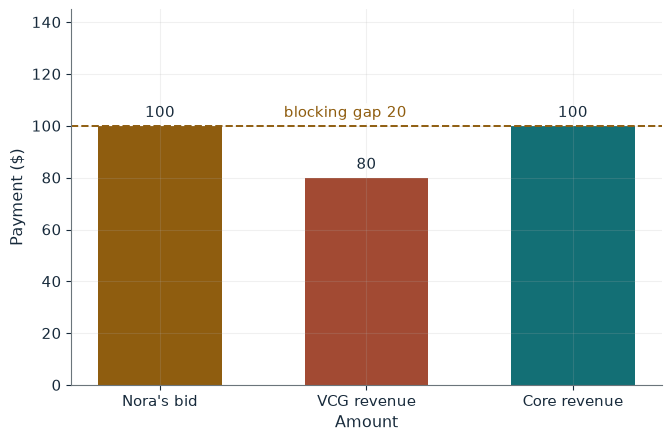

Winners                     Alice and Ben
VCG payment each            40
VCG revenue                 80
Blocking gap                20
Core payments (Alice, Ben)  (50, 50)
Nora's payment              none (she loses)

Worked steps:
  1. 60 + 60 = 120 > 100
  2. p_A = 100 - 60 = 40, p_B = 100 - 60 = 40
  3. VCG revenue = 40 + 40 = 80 < 100
  4. Core: p_A + p_B = 100, symmetric (50, 50)

The locals create 60 + 60 = 120, more than Nora's 100, so they win. Removing Alice leaves Nora's 100 as the best alternative, so Alice pays 100 - 60 = 40, and Ben pays the same. VCG revenue is 80, which is 20 below Nora's bid, so the seller and Nora could block. The core requires p_A + p_B >= 100; the symmetric minimum-revenue point is (50, 50), within each local's bid of 60.


In [10]:
show(core_picture(n=100))

## Practice

**1.** With Nora's bid at 110, what are the VCG and symmetric core payments of each local?

<details><summary>Answer</summary>

VCG: 110 - 60 = 50 each, revenue 100 < 110, blocked; core (55, 55).

</details>

**2.** With values (60, 30), what does the reserve of 50 add to realized revenue?

<details><summary>Answer</summary>

No reserve: 30. Reserve 50: max(30, 50) = 50, so 20 more; phi(60) = 2 x 60 - 100 = 20 > 0.

</details>

**3.** With a2 = 75 and b2 = 50, what are A's truthful and shaded payoffs?

<details><summary>Answer</summary>

Price 50: (100 - 50) + (75 - 50) = 75 truthful; shading gives 100 - 0 = 100, losing 75 - 50 = 25 of value.

</details>